# Prototype patch interactions in the Volleyball setup

In [1]:
%pylab
%load_ext autoreload
%autoreload 2

Using matplotlib backend: TkAgg
Populating the interactive namespace from numpy and matplotlib


In [2]:
import copy as copy
import numpy as np
import pylab
import matplotlib.pyplot as pl
import _volleyball as vball
import _sphere_points
import _patch as patch
from mpl_toolkits.mplot3d import Axes3D

In [3]:
# Generate a full layer
vb=vball.volleyball(n_wide=12,r_min=0.7,r_max=0.75) 
points,new_rad=vb.generate_layer(symmetric=True)
print (len(points))

4800


In [4]:
# Generate pathes in a layer
layer=[]
i=0
for p in points:
    pa=patch.patch(points[i],n_cell=20)
    i+=1
    layer.append(pa)

In [68]:
# Generate a single nbor
nbors=[]
nbors.append(layer[15])
new=vb.generate_nbor(layer[15].point)
new_patch=patch.patch(new)
nbors.append(new_patch)

# Generate a cluster of nbors
nbors=[]
nbpts=vb.generate_nbors()
for p in nbpts:
    print (p.id)
    new_patch=patch.patch(p)
    nbors.append(new_patch)

10
1
2
3
4
5
6
7
8
9
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27


In [26]:
len(nbors)

27

In [22]:
# Plot nbors and their guard zones
fig=plt.figure(figsize=(10, 10), dpi= 80, facecolor='w', edgecolor='k')
ax = fig.add_subplot(111, projection='3d')
ds=layer[0].size*3
cols=['r','g','b']
cols2=['c','m','navy']
i=0
for p in nbors:
    print (p.position)
    #if(in_range(p,posit,ds)):
        #print (p.point.id)
        #print('e1',p.point.e[:,0])
        #print('e2',p.point.e[:,1])
        #print('e3',p.point.e[:,2])
        #print ('p,theta,phi,r', p.point.xyz(),p.point.theta,p.point.phi,p.point.r)
    p.plot_patch(ax,rotate=True, alpha=0.5,color=cols[i])
    #p.plot_patch(ax,guards=True,rotate=True,color=cols2[i], alpha=0.4, linestyle='dashed')
    #plot_patch(ax,p,rotate=False, color='g')
    #plot_patch(ax,p,guards=True,rotate=True,color='r', alpha=0.5, linestyle='dashed')
    i+=1
    i=i%len(cols)
"""                                                                                                                                                    
Scaling is done from here...                                                                                                                           
"""
x_scale=1
y_scale=1
z_scale=1

scale=diag([x_scale, y_scale, z_scale, 1.0])
cale=scale*(1.0/scale.max())
scale[3,3]=1.0

def short_proj():
    return np.dot(Axes3D.get_proj(ax), scale)

ax.get_proj=short_proj
plt.tight_layout()
#ax.axes.set_xlim3d(left=-1, right=1) 
#ax.axes.set_ylim3d(bottom=-1, top=1) 
#ax.axes.set_zlim3d(bottom=-1, top=1) 
ax.view_init(elev=30.0, azim=35.)
plt.show()


[0.67419698 0.01729926 0.01729926]
[0.71054494 0.01823191 0.01823191]
[ 0.71054494 -0.01823191  0.01823191]
[ 0.70867615 -0.01818396  0.05464778]
[ 0.71054494 -0.01823191 -0.01823191]
[0.70867615 0.01818396 0.05464778]
[ 0.71054494  0.01823191 -0.01823191]
[0.70867492 0.05464775 0.01823191]
[0.70681104 0.05450402 0.05464778]
[ 0.70867492  0.05464775 -0.01823191]
[ 0.67419698 -0.01729926  0.01729926]
[ 0.67242379 -0.01725376  0.05185227]
[ 0.67419698 -0.01729926 -0.01729926]
[0.67242379 0.01725376 0.05185227]
[ 0.67419698  0.01729926 -0.01729926]
[0.67242262 0.05185224 0.01729926]
[0.67065409 0.05171586 0.05185227]
[ 0.67242262  0.05185224 -0.01729926]
[0.6397084  0.01641431 0.01641431]
[ 0.6397084  -0.01641431  0.01641431]
[ 0.63802591 -0.01637114  0.04919977]
[ 0.6397084  -0.01641431 -0.01641431]
[0.63802591 0.01637114 0.04919977]
[ 0.6397084   0.01641431 -0.01641431]
[0.63802481 0.04919973 0.01641431]
[0.63634675 0.04907033 0.04919977]
[ 0.63802481  0.04919973 -0.01641431]


In [23]:
#place a point a target is interested in
pa=nbors[0]
cell=[10,10,10]
pt=pa.cell2pos(cell)
pt_glob=pa.loc2glob(pt)
ax.scatter(pt_glob[0],pt_glob[1],pt_glob[2], color='r')
plt.show()

In [631]:
# The point location in source
pa2=nbors[1]
pt_loc = pa2.glob2loc(pt_glob)
cell_loc=pa2.pos2cell(pt_loc)
print (pt, pt_loc)
print (cell, cell_loc)

[0.0009876828200702237, 0.02074133922147585, 0.006913779740491951] [ 0.00093916 -0.01609219  0.0070331 ]
[12, 22, 15] [11  3 15]


In [632]:
# Go back from source point location to target
chk=pa.to_my_coords(pa2,pt_loc)
c2=pa.pos2cell(chk)
c3=pa.loc2glob(chk)
ax.scatter(c3[0],c3[1],c3[2], color='c')
print (chk, c2)

[0.00098768 0.02074134 0.00691378] [12 22 15]


In [633]:
# alternative to_my_coords formulation
chk2=pa.to_my_coords2(pa2,pt_loc)
c22=pa.pos2cell(chk2)
c32=pa.loc2glob(chk2)
ax.scatter(c32[0],c32[1],c32[2], color='m')
print (chk2, c22)

[0.00098768 0.02074134 0.00691378] [12 22 15]


# Check the index ranges and guard zone loading
### Positions are in target coordinate system.

In [635]:
# For a single nbor
# targets are offset in Y
target=nbors[0]
source=nbors[1]
# add memory slots
target.add_mem()
source.add_mem()
#fill memory with vertical velocity
v=[0,0,1]*target.d
vt=np.matmul(v,target.point.e)
vs=np.matmul(v,source.point.e)
print (vt, vs) # values velocities get in local frames of reference in patches
target.mem[:,:,:,0]=vt[0]
target.mem[:,:,:,1]=vt[1]
target.mem[:,:,:,2]=vt[2]
#
source.mem[:,:,:,0]=vs[0]
source.mem[:,:,:,1]=vs[1]
source.mem[:,:,:,2]=vs[2]

[ 1.97471568e-03 -1.29927199e-06  5.06526754e-05] [ 1.97471225e-03 -3.90466612e-06  5.06526754e-05]


In [69]:
# For cluster of nbors
target= nbors.pop(0)
target.add_mem()
#fill memory with vertical velocity
v=[0,0,1]*target.d
vt=np.matmul(v,target.point.e)
target.mem[:,:,:,0]=vt[0]
target.mem[:,:,:,1]=vt[1]
target.mem[:,:,:,2]=vt[2]
for p in nbors:
    p.add_mem()
    vs=np.matmul(v,p.point.e)
    p.mem[:,:,:,0]=vs[0]
    p.mem[:,:,:,1]=vs[1]
    p.mem[:,:,:,2]=vs[2]



In [70]:
# Flip values in guard zones. A simple way to check, that nbors are providing good values. If the flipped values are later replaced with correct numbers, we can be sure, that the guard zone loading works.
def flip_vals(tgt,lt,ut):
    outside=np.zeros(3,dtype='bool')
    for i in range (lt[0],ut[0]+1):
        outside[0]= i<tgt.li[0] or i>tgt.ui[0]
        for j in range (lt[1],ut[1]+1):
            outside[1]= j<tgt.li[1] or j>tgt.ui[1]
            for k in range (lt[2],ut[2]+1):
                outside[2]= k<tgt.li[2] or k>tgt.ui[2]
                if any(outside):
                    tgt.mem[i,j,k,:]=-tgt.mem[i,j,k,:]

In [73]:
flip_vals(target,target.lb,target.ub)
target.mem[12,:,12,:]

array([ 0.,  0., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
       10., 10., 10., 10., 10., 10., 10., 10., 10.,  0.,  0.])

In [72]:
target.filled=np.zeros((target.gn[0]+1,target.gn[1]+1,target.gn[2]+1))
l=target.li
u=target.ui+1
target.filled[l[0]:u[0],l[1]:u[1],l[2]:u[2]]=target.point.id

In [75]:
for i in range(0,target.gn[0]+1):
    for j in range(0,target.gn[1]+1):
        for k in range(0,target.gn[2]+1):
            if (target.filled[i,j,k])==0:
                print ('not filled',)

In [38]:
#values in source - sanity check
nbors[4].mem[12,:,12,:]

array([[-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06,  1.44058200e-04],
       [-1.86876779e-03, -3.68545561e-06

In [74]:
for src in nbors:
    source_to_target(target,src)

78856470148
7 -0.02249178856470148 0.0224917885647015
-0.02249178856470148 -0.022491788564701496 -0.022491788564701496
0.0224917885647015 0.0224917885647015 0.0224917885647015
sl, su [-0.01975366 -0.01975366 -0.01975366] [0.01975366 0.01975366 0.01975366]
sl, su [-0.05716623 -0.05709252  0.01682599] [-0.01573742 -0.01566736  0.05218265]
fl, fu [-0.02249279 -0.02249279  0.01682499] [-0.01573642 -0.01566636  0.02249279]
lt, ut [-1 -1 20] [ 4  4 24]
lt,ut [ 0  0 20] [ 4  4 23]
4
tl, tu [-0.02249179 -0.02249179 -0.02249179] [0.02249179 0.02249179 0.02249179]
0 -0.02249178856470148 -0.02249178856470148
1 -0.02249178856470148 0.02249178856470148
2 -0.02249178856470148 0.02249178856470148
3 -0.02249178856470148 0.02249178856470148
4 -0.02249178856470148 0.02249178856470148
5 -0.02249178856470148 0.02249178856470148
6 -0.02249178856470148 0.02249178856470148
7 -0.02249178856470148 0.0224917885647015
-0.02249178856470148 -0.022491788564701496 -0.022491788564701496
0.0224917885647015 0.022491788

In [639]:
# Plot velocity vectors
fig = plt.figure()
ax = fig.gca(projection='3d')
n=2
x=target.r[0][::n]
y=target.r[1][::n]
z=target.r[2][::n]
x,y,z=np.meshgrid(x,y,z)
vx=target.mem[::n,::n,::n,0]
vy=target.mem[::n,::n,::n,1]
vz=target.mem[::n,::n,::n,2]
ax.quiver(x,y,z,vx,vy,vz)
plt.show()

In [67]:
def source_to_target(target,source):
    tl=-target.size*0.5-target.ng*target.d
    tu=target.size*0.5+target.ng*target.d
    eps = 1e-6
    print ('tl, tu', tl,tu)
    minx=999999
    maxx=-99999999
    miny=999999
    maxy=-99999999
    minz=999999999
    maxz=-9999999
    t_corners=target.all_corners(guards=True)
    for i in range(8):
        minx=min(minx,t_corners[i][0])
        maxx=max(maxx,t_corners[i][0])
        miny=min(miny,t_corners[i][1])
        maxy=max(maxy,t_corners[i][1])
        minz=min(minz,t_corners[i][2])
        maxz=max(maxz,t_corners[i][2])
        print (i, minx, maxx)

    print (minx,miny,minz)
    print (maxx,maxy,maxz)
    tlc=[minx,miny,minz]
    tuc=[maxx,maxy,maxz]
    for i in range(3):
        tl[i]=min(tl[i],tlc[i])
        tu[i]=max(tu[i],tuc[i])
    # get src position and orientation in target coordinates
    src_p, src_e=target.get_position(source)
    # get src corners in src local coordinates
    sl = -source.size*0.5
    su =  source.size*0.5
    print ('sl, su', sl, su)
    # rotate src corners to tgt coordinates
    sl = np. matmul(src_e,sl)
    su = np.matmul (src_e,su)
    # add relative position to corner values
    sl += src_p
    su += src_p
    print ('sl, su', sl, su)
    # get ranges
    fl=np.zeros(3)
    fu=np.zeros(3)
    for i in range(3):
        fl[i] = max(tl[i],sl[i])-eps
        fu[i] = min(tu[i],su[i])+eps
    print ('fl, fu', fl, fu)
    lt = np.zeros(3,dtype='int')
    ut = np.zeros(3,dtype='int')
    lt[:] = np.floor(fl/target.d+target.o)
    ut[:] = np.ceil(fu/target.d+target.o)
    print ('lt, ut', lt, ut)
    for i in range(3):
        lt[i] = max(lt[i],target.lb[i])
        ut[i] = min(ut[i],target.ub[i])
    print ('lt,ut', lt, ut)
    print (int(ut[0]))
    #flip_vals(target,lt,ut)
    target.from_source(lt,ut,source,filled=True)
    #for i in range(lt[0],ut[0]+1):
    #    for j in range(lt[1],ut[1]+1):
    #        for k in range(lt[2],ut[2]+1):
    #            cell=[i,j,k]
    #            pt=target.cell2pos(cell)
    #            pt_glob=target.loc2glob(pt)
    #            ax.scatter(pt_glob[0],pt_glob[1],pt_glob[2], color='r')


In [446]:
def in_range(p, position,ds):
    pos=p.position
    l=position-ds
    u=position+ds
    in_range=True
    for i in range(0,3):
        if (pos[i]<l[i] or pos[i]>u[i]):
            in_range=False
    return in_range

In [425]:
fig=plt.figure(figsize=(8, 8), dpi= 80, facecolor='w', edgecolor='k')
ax = fig.add_subplot(111, projection='3d')
# Create a sphere
r = 1

#ax.plot_surface(x, y, z,  rstride=1, cstride=1, color='r', alpha=0.1, linewidth=0)
#ax.plot_wireframe(x, y, z,  rstride=1, cstride=1, color='k', alpha=0.2, linewidth=1.5)
plot_patch(ax,p,rotate=True)
plot_patch(ax,p,rotate=False, color='g')
plot_patch(ax,p,guards=True,rotate=True,color='r', alpha=0.5, linestyle='dashed')
"""                                                                                                                                                    
Scaling is done from here...                                                                                                                           
"""
x_scale=1
y_scale=1
z_scale=1

scale=diag([x_scale, y_scale, z_scale, 1.0])
cale=scale*(1.0/scale.max())
scale[3,3]=1.0

def short_proj():
    return np.dot(Axes3D.get_proj(ax), scale)

ax.get_proj=short_proj
plt.tight_layout()

ax.view_init(elev=30.0, azim=35.)
plt.show()


AttributeError: 'point_on_sphere' object has no attribute 'li'

#### Generate patches

In [133]:
theta0=np.arctan(np.sqrt(0.5))
dtheta=theta0/12
radius=1.0
point=point_on_sphere(dtheta)
point.size= radius*dtheta/(1-dtheta)
save=copy.deepcopy(point)
points=[]
point.go_north(0.5*dtheta)
point.go_east(0.5*dtheta)
while(point.is_inside(theta0,dtheta)):
    point.r = radius - point.size/2
    save = copy.deepcopy(point)
    while (point.is_inside(theta0,dtheta)):
        symmetries(point, points)
        point.east_west()
        symmetries(point, points)
        point.north_south()
        symmetries(point, points)
        point.east_west()
        symmetries(point, points)
        point.north_south()
        # back to start
        point.go_east(dtheta)
    point=save
    # next row
    point.go_north(dtheta)
    save=copy.copy(point)

NameError: name 'symmetries' is not defined

In [38]:
face[0]

[(0.9993422624976582, 0.025642175134121318, 0.025642176983488345)]

#### Plot patch tops and face boundaries:

In [29]:
def norm(r):
    return np.sqrt(np.dot(r,r))
def plot_top(p,size):
    rhat=p/norm(p)
    north=np.array([0,0,1])
    east=np.cross(north,rhat)
    east=east/norm(east)
    north=np.cross(rhat,east)
    north=north*size
    east=east*size
    face=[p+(north+east)/2,p+(north-east)/2,
          p-(north+east)/2,p-(north-east)/2,p+(north+east)/2]
    face=np.transpose(face)
    pl.plot(face[1],face[2])
# Plot patch tops
clf()
face=[]
for p in points:
    face.append(array(p.xyz()))   
    #face.append([+p[0],-p[1],+p[2]])
    #face.append([+p[0],+p[1],-p[2]])   
    #face.append([+p[0],-p[1],-p[2]])
for p in face:
    plot(p[1],p[2],'+')
    plot_top(p,l1.dtheta)
# Ploit VB face boundaries
theta=l1.theta0
phi=linspace(-np.pi/4,np.pi/4)
pl.plot(np.cos(theta)*np.cos(phi),np.cos(theta)*np.sin(phi))
pl.plot(np.cos(phi),np.sin(phi))
theta=linspace(0,l1.theta0)
phi=np.pi/4
pl.plot(np.cos(theta)*np.cos(phi),np.cos(theta)*np.sin(phi));
phi=-np.pi/4
pl.plot(np.cos(theta)*np.cos(phi),np.cos(theta)*np.sin(phi));

##### Complete sphere

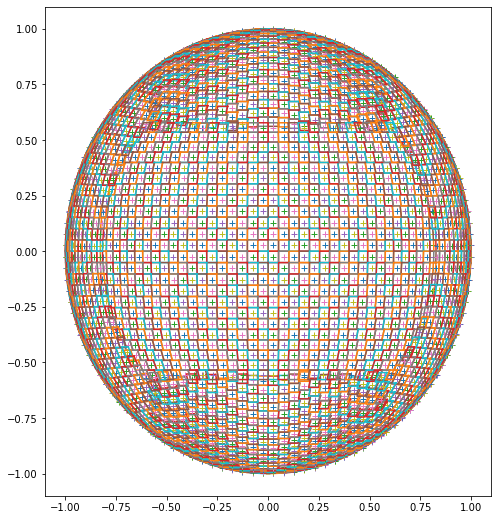

In [28]:
pl.figure(figsize=(8,9))
pl.clf()
faces=[]
for p in face:
    faces.append([+p[0],+p[1],+p[2]])
    faces.append([-p[0],-p[1],-p[2]])
    p=[p[1],p[2],p[0]]
    faces.append([+p[0],+p[1],+p[2]])
    faces.append([-p[0],-p[1],-p[2]])
    p=[p[1],p[2],p[0]]
    faces.append([+p[0],+p[1],+p[2]])
    faces.append([-p[0],-p[1],-p[2]])
for p in faces:
    if p[0]>0:
        pl.plot(p[1],p[2],'+')
        plot_top(p,dtheta)